# ۰۶ - تحلیل رفتار پرداخت

پاسخ به سؤال‌های بخش ۸ صورت‌مسئله: روش‌های پرداخت، تعداد اقساط و رابطه مبلغ و اقساط.

## ۲. سؤال‌های کسب‌وکاری

1. هر روش پرداخت چند تراکنش دارد و سهم آن چقدر است؟
2. مجموع و متوسط مبلغ پرداخت هر روش چقدر است؟
3. توزیع تعداد اقساط چگونه است؟
4. چه تعداد پرداخت بدون قسط یا یک‌قسطی است؟
5. آیا مبلغ بالاتر با اقساط بیشتر همراه است؟

## ۱. عنوان و هدف

پاسخ به سؤال‌های بخش ۸ صورت‌مسئله: روش‌های پرداخت، تعداد اقساط و رابطه مبلغ و اقساط.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from olist_analysis import metrics as M
from olist_analysis.config import FIGURES_DIR, REPORTS_DIR, TABLES_DIR
from olist_analysis.font_utils import persian_available
from olist_analysis.features import load_dataset
from olist_analysis.pipeline import load_headline

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

ds = load_dataset()
headline = load_headline()
print("Persian font registered for charts:", persian_available())
print(f"orders={len(ds.orders):,}  items={len(ds.items):,}  "
      f"delivered={len(ds.delivered):,}  reviewed={len(ds.reviews_per_order):,}")


Persian font registered for charts: True
orders=99,441  items=112,650  delivered=96,470  reviewed=98,673


## ۴. روش محاسبه

هر ردیف جدول پرداخت یک تراکنش است و با سفارش یک‌به‌یک نیست؛ بنابراین تعداد تراکنش، تعداد سفارش و تعداد مشتری سه مخرج متفاوت دارند.

## ۵. بررسی کیفیت داده مرتبط

### تفکیک دقیق جامعه‌های آماری

In [2]:
display(M.payment_reconciliation(ds))

,population,n,note
0,payment rows (transactions),103886,one row per payment transaction
1,unique orders in payments,99440,an order may pay with several transactions
2,orders in orders table,99441,the analysis base for order metrics
3,orders with no payment row,1,created / canceled orders
4,"customer rows, i.e. orders",99441,customer_id is one row per order
5,unique buyers (people),96096,customer_unique_id is the physical person


## ۶. تحلیل عددی

### ۸.۱ تا ۸.۳ روش‌های پرداخت

In [3]:
display(M.payment_type_summary(ds))

,payment_type,n_transactions,total_payment_value,mean_payment_value,median_payment_value,n_orders,mean_installments,pct_transactions_with_installment_gt1,pct_transactions,pct_payment_value,pct_orders
0,credit_card,76795,12542084.19,163.32,106.87,76505,3.51,66.8507,73.9224,78.3446,76.9358
1,boleto,19784,2869361.27,145.03,93.89,19784,1.00,0.0000,19.0440,17.9236,19.8954
2,voucher,5775,379436.87,65.70,39.28,3866,1.00,0.0000,5.5590,2.3702,3.8878
3,debit_card,1529,217989.79,142.57,89.30,1528,1.00,0.0000,1.4718,1.3617,1.5366
4,not_defined,3,0.00,0.00,0.00,3,1.00,0.0000,0.0029,0.0000,0.0030


### ۸.۴ توزیع تعداد اقساط

In [4]:
display(M.installment_distribution(ds))

,payment_installments,n_transactions,pct_transactions,cum_pct,bucket
0,1,52546,50.5814,50.5814,1
1,2,12413,11.9489,62.5303,2
2,3,10461,10.0699,72.6002,3
3,4,7098,6.8326,79.4328,4
4,5,5239,5.0431,84.4759,5
5,6,3920,3.7734,88.2493,6
6,7,1626,1.5652,89.8145,7
7,8,4268,4.1084,93.9229,8
8,9,644,0.6199,94.5428,9
9,10,5328,5.1288,99.6716,10


### ۸.۵ پرداخت‌های بدون قسط یا یک‌قسطی

In [5]:
display(pd.Series({k: v for k, v in M.zero_or_single_installments(ds).items() if k != "by_type"}, name="value"))
display(M.zero_or_single_installments(ds)["by_type"])

n_transactions            103886.0000
n_zero_installments            2.0000
n_single_installment       52546.0000
n_zero_or_single           52548.0000
pct_zero_or_single            50.5824
pct_single_of_positive        50.5814
Name: value, dtype: float64

,payment_type,n_transactions,n_single_shot,pct_single_shot
0,credit_card,76795,25457,33.1493
1,boleto,19784,19784,100.0000
2,voucher,5775,5775,100.0000
3,debit_card,1529,1529,100.0000
4,not_defined,3,3,100.0000


### ۸.۶ تعداد اقساط به تفکیک روش پرداخت

In [6]:
display(M.installments_by_type_summary(ds))

,payment_type,n_transactions,min_installments,median_installments,mean_installments,max_installments,n_unique_installment_values
0,credit_card,76795,0,3.0,3.51,24,24
1,boleto,19784,1,1.0,1.00,1,1
2,voucher,5775,1,1.0,1.00,1,1
3,debit_card,1529,1,1.0,1.00,1,1
4,not_defined,3,1,1.0,1.00,1,1


### ۸.۷ رابطه مبلغ پرداخت و تعداد اقساط

In [7]:
bins, stats = M.combined_payment_vs_installments(ds)
display(pd.Series(stats, name="value"))
display(bins[["value_band", "n_transactions", "median_value", "mean_installments", "pct_multi_installment"]])

n_transactions                          103884.0000
n_orders_with_payment                    99440.0000
spearman_rho_transaction_level               0.4111
spearman_rho_credit_card_only                0.4776
spearman_rho_order_level                     0.3817
mean_installments_lowest_decile              1.2092
mean_installments_highest_decile             5.3260
pct_multi_installment_lowest_decile         15.0556
pct_multi_installment_highest_decile        73.4983
Name: value, dtype: float64

,value_band,n_transactions,median_value,mean_installments,pct_multi_installment
0,0-35,10428,26.20,1.21,15.0556
1,35-49,10362,42.41,1.65,30.9593
2,49-64,10376,56.82,1.95,36.3820
3,64-80,10388,71.78,2.25,42.9342
4,80-100,10555,89.67,2.55,45.3340
5,100-123,10222,111.43,2.97,56.6914
6,123-154,10389,137.60,3.08,59.1010
7,154-196,10390,171.84,3.50,65.8133
8,196-297,10386,231.13,4.05,68.6694
9,"297-13,664",10388,437.65,5.33,73.4983


## ۷. نمودارها

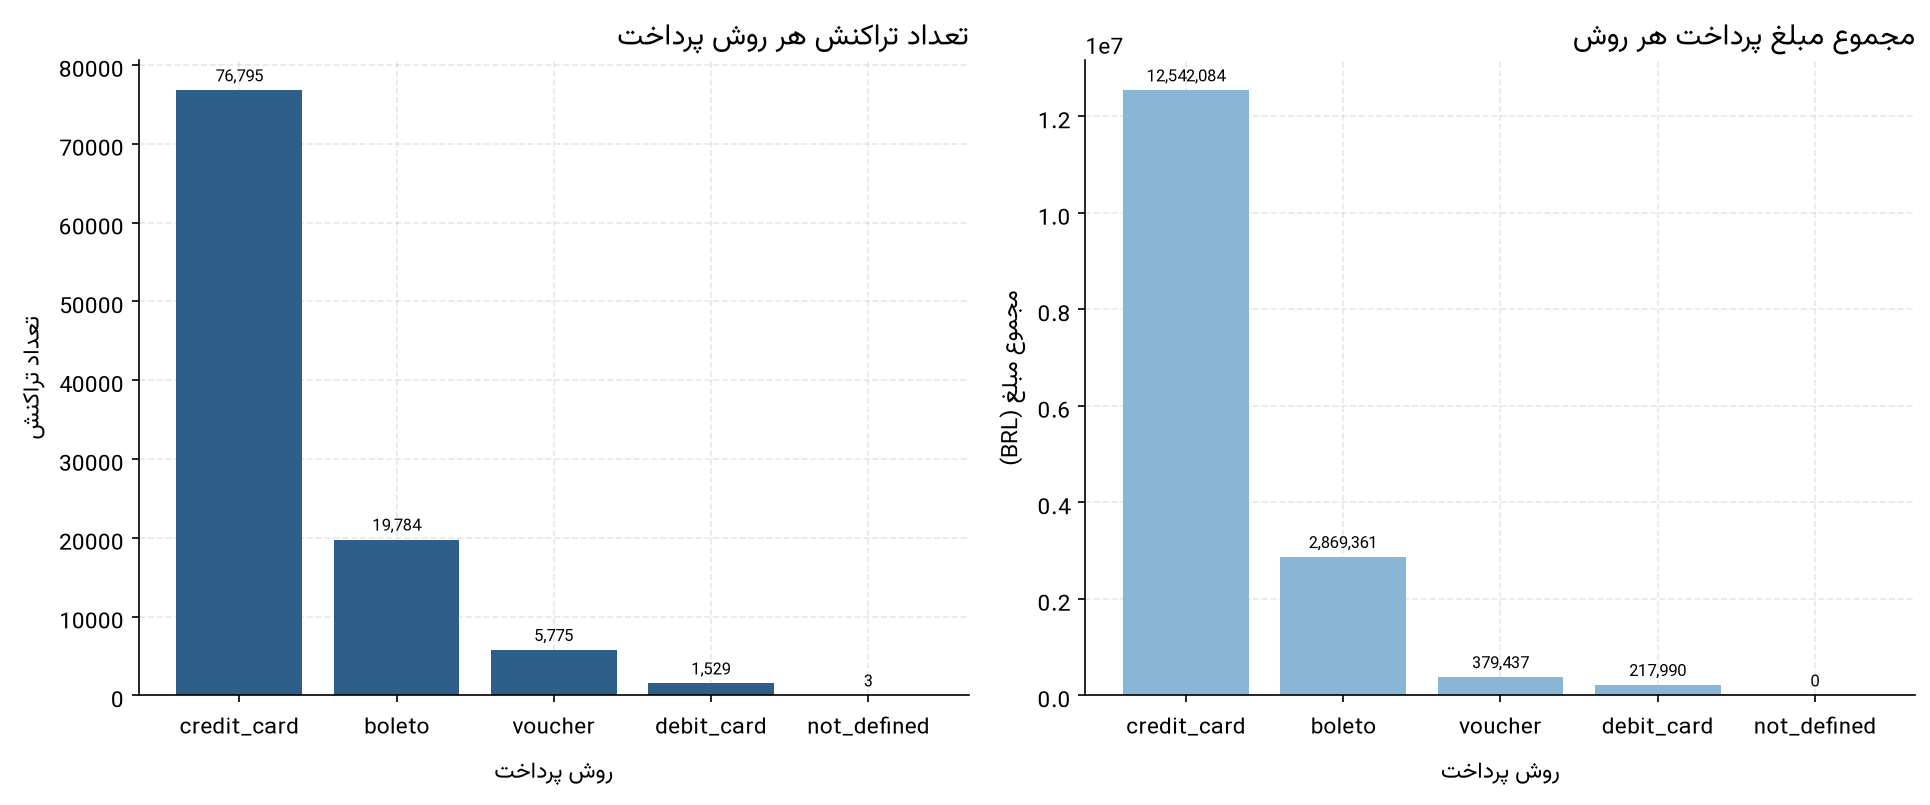

نمودار ۱۲ - تعداد تراکنش و مجموع مبلغ به تفکیک روش پرداخت


In [8]:
display(Image(filename=str(FIGURES_DIR / "fig_12_payment_types.png"), width=920))
caption = FIGURES_DIR / "fig_12_payment_types.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

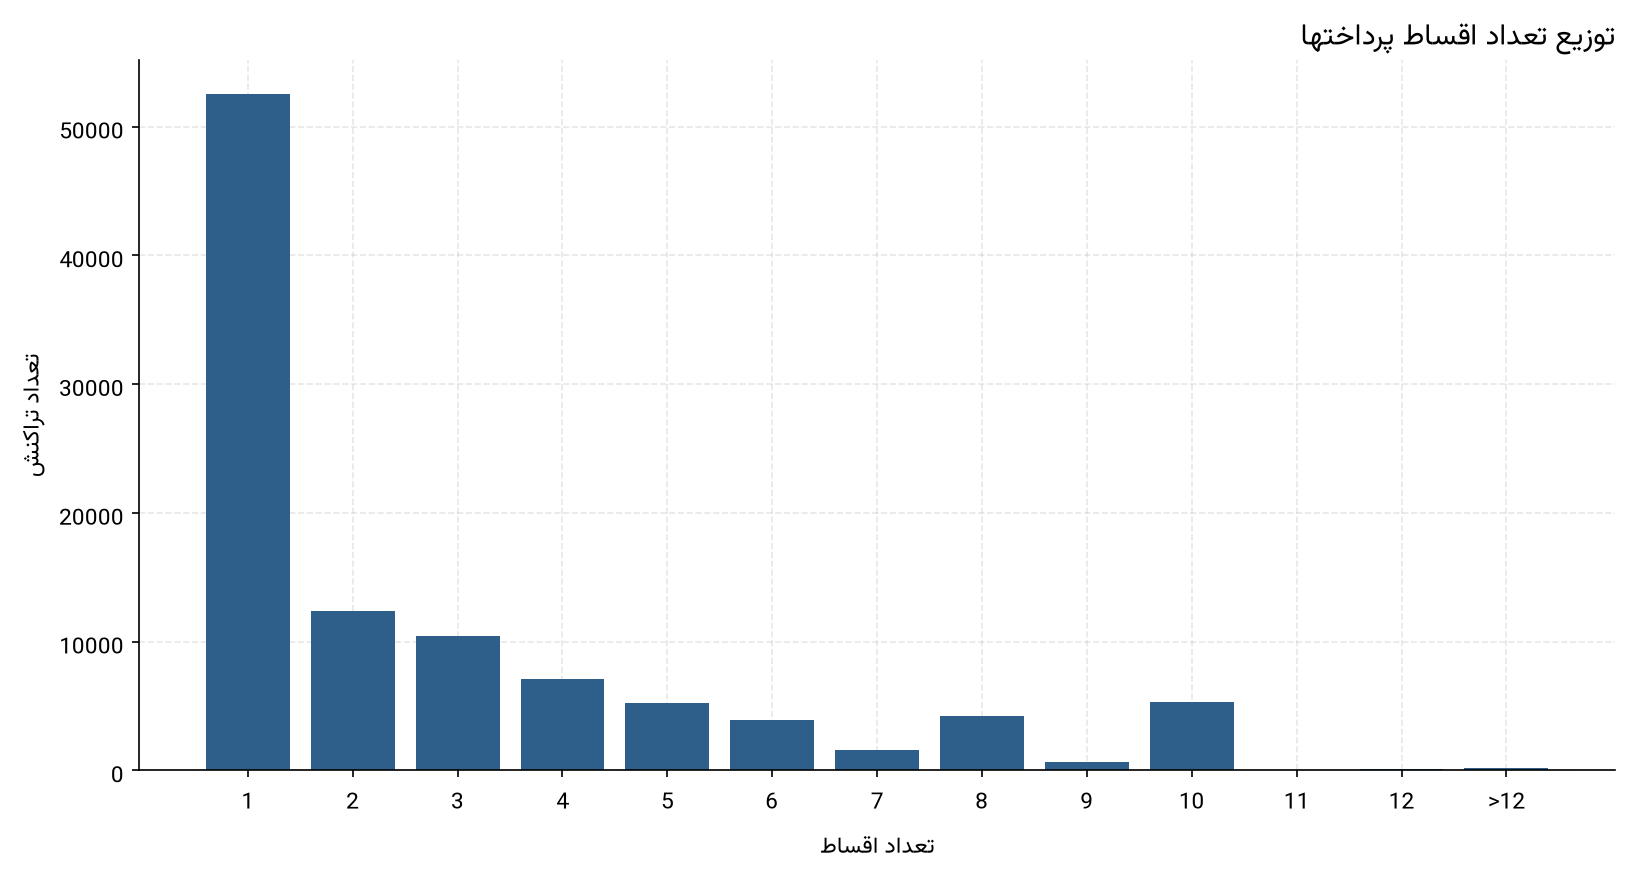

نمودار ۱۳ - توزیع تعداد اقساط؛ بیش از نیمی از تراکنشها یکقسطی هستند


In [9]:
display(Image(filename=str(FIGURES_DIR / "fig_13_installments_distribution.png"), width=920))
caption = FIGURES_DIR / "fig_13_installments_distribution.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

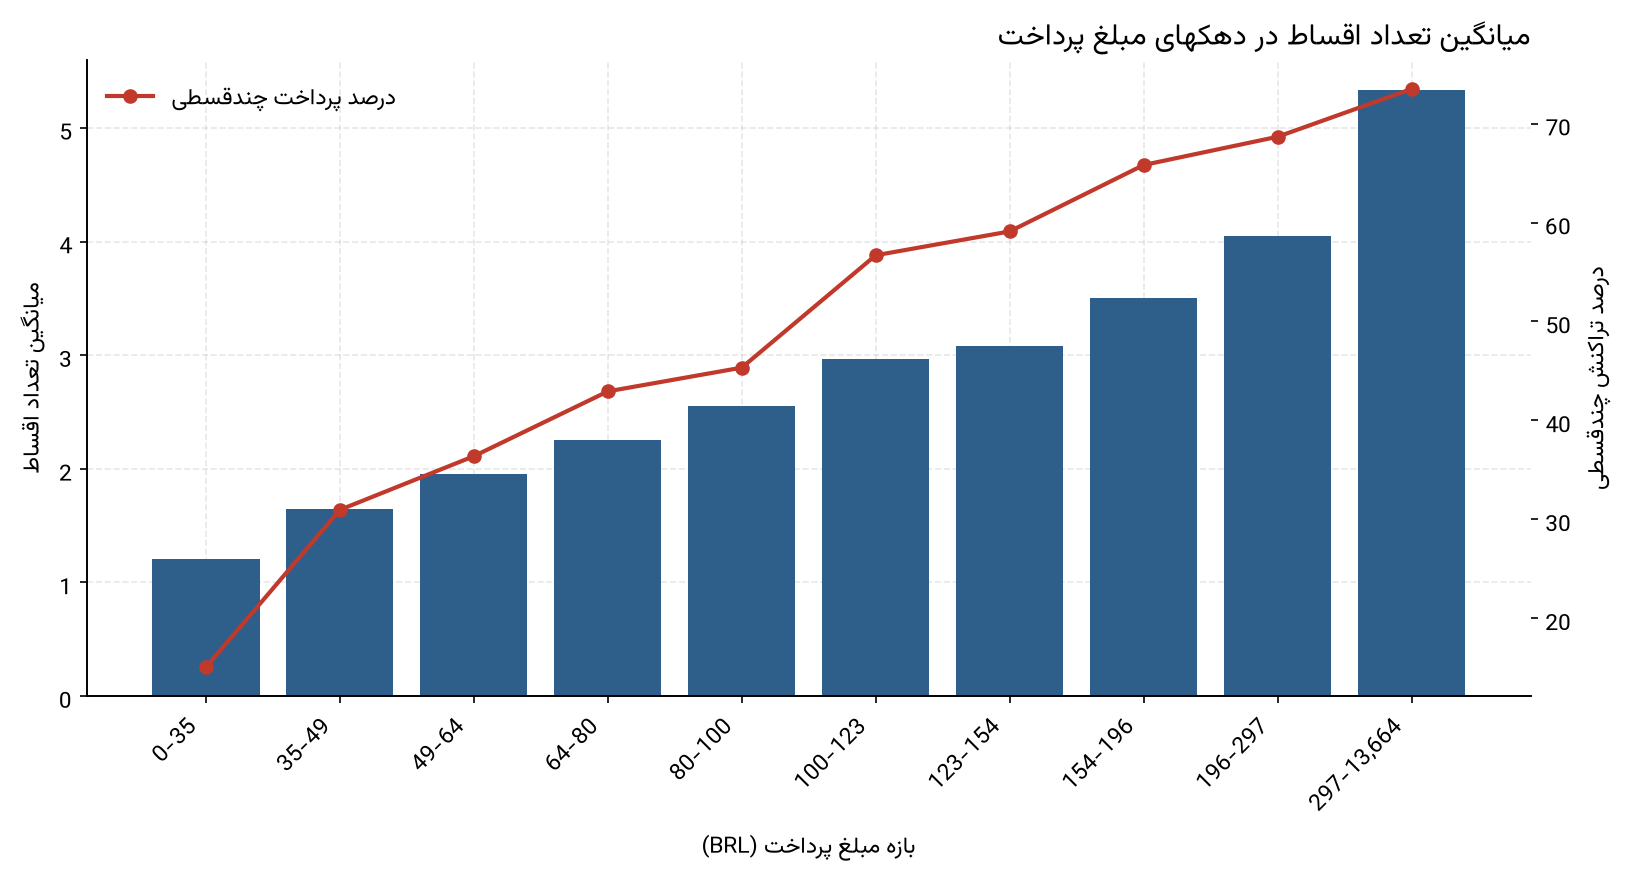

نمودار ۱۴ - با افزایش مبلغ پرداخت، تعداد اقساط و سهم پرداخت چندقسطی زیاد میشود


In [10]:
display(Image(filename=str(FIGURES_DIR / "fig_14_payment_value_vs_installments.png"), width=920))
caption = FIGURES_DIR / "fig_14_payment_value_vs_installments.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

## ۸. یافته‌های واقعی

- ۱۰۳٬۸۸۶ تراکنش پرداخت برای ۹۹٬۴۴۰ سفارش ثبت شده است؛ تنها ۱ سفارش ردیف پرداخت ندارد.
- کارت اعتباری با ۷۶٬۷۹۵ تراکنش (۷۳.۹۲ درصد) و ۷۸.۳۴ درصد ارزش پرداخت، روش غالب است. بولتو با ۱۹٬۷۸۴ تراکنش در جای دوم است.
- ۵۲٬۵۴۶ تراکنش (۵۰.۵۸ درصد) یک‌قسطی هستند و فقط ۲ تراکنش مقدار صفر برای تعداد اقساط دارند که هر دو بخشی از یک پرداخت چندمرحله‌ای‌اند.
- فقط کارت اعتباری اقساط دارد: میانگین ۳.۵۱ قسط و بیشینه ۲۴. بولتو، ووچر و کارت نقدی همیشه یک‌قسطی هستند.
- رابطه مبلغ پرداخت و تعداد اقساط مثبت است (اسپیرمن ۰.۴۱۱ در سطح تراکنش و ۰.۴۷۸ برای کارت اعتباری): میانگین اقساط از ۱.۲۱ در کم‌مبلغ‌ترین دهک به ۵.۳۳ در پرمبلغ‌ترین دهک می‌رسد.

## ۹. تفسیر کسب‌وکاری

ساختار اقساط عملاً یک ابزار کارت اعتباری است و برای مبالغ بالاتر استفاده می‌شود؛ بنابراین اقساط یک اهرم واقعی برای خریدهای گران است. تمرکز بالای پرداخت روی یک روش نیز ریسک عملیاتی و ریسک نرخ کارمزد را بالا می‌برد.

## ۱۰. محدودیت‌های تحلیل

همبستگی مشاهده‌شده رابطه علّی نیست و داده شامل درآمد، اعتبار یا ترجیحات مشتری نیست. همچنین ۹ ردیف با ارزش صفر (ووچر و `not_defined`) در محاسبات میانگین باقی مانده‌اند.

## ۱۱. نتیجه‌گیری

اقساط بیشتر برای مبالغ بالاتر یک الگوی روشن و قابل استفاده در سیاست فروش است؛ اما وابستگی به یک روش پرداخت و نرخ بالای پرداخت یک‌قسطی برای تیم مالی ریسک محسوب می‌شود.